# Lab 4 FDSAI (2026-2027) – Confidence intervals
Run all cells from top to bottom. In Exercise 2 you will be asked to upload the NHANES file from Lab 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## Student t table (Tabelul B)
The critical values of the Student distribution are taken from **Tabelul B** (quantiles of order $1-\alpha$). It is typed below as a dictionary: the keys are the degrees of freedom (the row `n` of the table, `inf` = last row $\infty$) and the columns correspond to the quantile orders $1-\alpha$.

For a two-sided interval with confidence level `conf`, the needed quantile has order $1-\alpha/2$, so the column is: 90% → **0.950**, 95% → **0.975**, 99% → **0.995**.

When the exact number of degrees of freedom is not in the table (e.g. df = 99 or df = 49), the **nearest tabulated row** is used (df = 99 → row 100, df = 49 → row 50), and every df above 100 uses the last row ($\infty$).

In [2]:
# Tabelul B: quantiles t_{1-alpha} of the Student distribution
T_COLS = [0.60, 0.75, 0.90, 0.950, 0.975, 0.990, 0.995, 0.999]   # orders 1 - alpha
T_TABLE = {
    1:  [0.325, 1.000, 3.078, 6.314, 12.706, 31.821, 63.657, 318.313],
    2:  [0.289, 0.816, 1.886, 2.920, 4.303, 6.965, 9.925, 22.327],
    3:  [0.277, 0.765, 1.638, 2.353, 3.182, 4.541, 5.841, 10.215],
    4:  [0.271, 0.741, 1.533, 2.132, 2.776, 3.747, 4.604, 7.173],
    5:  [0.267, 0.727, 1.476, 2.015, 2.571, 3.365, 4.032, 5.893],
    6:  [0.265, 0.718, 1.440, 1.943, 2.447, 3.143, 3.707, 5.208],
    7:  [0.263, 0.711, 1.415, 1.895, 2.365, 2.998, 3.499, 4.782],
    8:  [0.262, 0.706, 1.397, 1.860, 2.306, 2.896, 3.355, 4.499],
    9:  [0.261, 0.703, 1.383, 1.833, 2.262, 2.821, 3.250, 4.296],
    10: [0.260, 0.700, 1.372, 1.812, 2.228, 2.764, 3.169, 4.143],
    11: [0.260, 0.697, 1.363, 1.796, 2.201, 2.718, 3.106, 4.024],
    12: [0.259, 0.695, 1.356, 1.782, 2.179, 2.681, 3.055, 3.929],
    13: [0.259, 0.694, 1.350, 1.771, 2.160, 2.650, 3.012, 3.852],
    14: [0.258, 0.692, 1.345, 1.761, 2.145, 2.624, 2.977, 3.787],
    15: [0.258, 0.691, 1.341, 1.753, 2.131, 2.602, 2.947, 3.733],
    16: [0.258, 0.690, 1.337, 1.746, 2.120, 2.583, 2.921, 3.686],
    17: [0.257, 0.689, 1.333, 1.740, 2.110, 2.567, 2.898, 3.646],
    18: [0.257, 0.688, 1.330, 1.734, 2.101, 2.552, 2.878, 3.610],
    19: [0.257, 0.688, 1.328, 1.729, 2.093, 2.539, 2.861, 3.579],
    20: [0.257, 0.687, 1.325, 1.725, 2.086, 2.528, 2.845, 3.552],
    21: [0.257, 0.686, 1.323, 1.721, 2.080, 2.518, 2.831, 3.527],
    22: [0.256, 0.686, 1.321, 1.717, 2.074, 2.508, 2.819, 3.505],
    23: [0.256, 0.685, 1.319, 1.714, 2.069, 2.500, 2.807, 3.485],
    24: [0.256, 0.685, 1.318, 1.711, 2.064, 2.492, 2.797, 3.467],
    25: [0.256, 0.684, 1.316, 1.708, 2.060, 2.485, 2.787, 3.450],
    26: [0.256, 0.684, 1.315, 1.706, 2.056, 2.479, 2.779, 3.435],
    27: [0.256, 0.684, 1.314, 1.703, 2.052, 2.473, 2.771, 3.421],
    28: [0.256, 0.683, 1.313, 1.701, 2.048, 2.467, 2.763, 3.408],
    29: [0.256, 0.683, 1.311, 1.699, 2.045, 2.462, 2.756, 3.396],
    30: [0.256, 0.683, 1.310, 1.697, 2.042, 2.457, 2.750, 3.385],
    40: [0.255, 0.681, 1.303, 1.684, 2.021, 2.423, 2.704, 3.307],
    50: [0.255, 0.680, 1.299, 1.676, 2.009, 2.403, 2.678, 3.261],
    60: [0.254, 0.679, 1.296, 1.671, 2.000, 2.390, 2.660, 3.232],
    100: [0.254, 0.677, 1.290, 1.660, 1.984, 2.364, 2.626, 3.174],
    "inf": [0.253, 0.674, 1.282, 1.645, 1.960, 2.326, 2.576, 3.090],
}
T_DF_KEYS = [k for k in T_TABLE if k != "inf"]    # tabulated degrees of freedom: 1..30, 40, 50, 60, 100

def t_table(df, conf):
    # Critical value t_{1-alpha/2} read from Tabelul B for a two-sided interval with level `conf`.
    # Returns (value, row used). Uses the nearest tabulated row; every df > 100 uses the infinity row.
    order = 1 - (1 - conf) / 2                                    # column to read, e.g. 0.90 -> 0.950
    col = [i for i, c in enumerate(T_COLS) if np.isclose(c, order)]
    if not col:
        raise ValueError(f"Confidence level {conf} is not available in the table")
    if df > 100:
        row = "inf"
    else:
        row = min(T_DF_KEYS, key=lambda k: (abs(k - df), k))      # nearest row (ties -> smaller df)
    return T_TABLE[row][col[0]], row

# Sanity check of the typed table against the exact SciPy quantiles (tiny rounding differences are allowed)
for key, vals in T_TABLE.items():
    df_ = np.inf if key == "inf" else key
    for c, v in zip(T_COLS, vals):
        assert abs(stats.t.ppf(c, df_) - v) < 0.002 + 0.0005 * v, (key, c)
print("Table typed correctly; example: df = 11, 90% CI ->", t_table(11, 0.90))

Table typed correctly; example: df = 11, 90% CI -> (1.796, 11)


## Exercise 1 – Entry-level computer engineer salaries
The salaries are assumed to be normally distributed with unknown mean and variance, so:
- the CI for the mean uses the **Student t** distribution (critical value read from Tabelul B): $\bar{x} \pm t_{1-\alpha/2,\,n-1}\, s/\sqrt{n}$
- the CI for the standard deviation uses the **chi-square** distribution (its quantiles are computed with SciPy): $\left[\sqrt{\frac{(n-1)s^2}{\chi^2_{1-\alpha/2,\,n-1}}},\ \sqrt{\frac{(n-1)s^2}{\chi^2_{\alpha/2,\,n-1}}}\right]$

In [3]:
salaries = np.array([1074.67, 1011.17, 1089.77, 1177.30, 1001.58, 1001.59,
                     1182.92, 1101.74, 978.05, 1079.26, 978.66, 978.43])

n = len(salaries)
x_bar = salaries.mean()
s = salaries.std(ddof=1)      # sample standard deviation (n - 1 in the denominator)
print(f"n = {n}, sample mean = {x_bar:.4f}, sample std = {s:.4f}")

n = 12, sample mean = 1054.5950, sample std = 74.4234


### 1a) 90% confidence interval for the mean

In [4]:
conf = 0.90
alpha = 1 - conf

# Critical value from Tabelul B: row df = n - 1 = 11, column 1 - alpha/2 = 0.950
t_crit, row_used = t_table(n - 1, conf)
std_err = s / np.sqrt(n)                            # standard error of the mean
margin = t_crit * std_err                           # margin of error
ci_mean_small = (x_bar - margin, x_bar + margin)

print(f"Table row (df) = {row_used}, column = {1 - alpha / 2:.3f}  ->  t critical value = {t_crit}")
print(f"Standard error = {std_err:.4f}, margin of error = {margin:.4f}")
print(f"90% CI for the mean: [{ci_mean_small[0]:.2f}, {ci_mean_small[1]:.2f}]")

# Cross-check with the exact SciPy interval (tiny differences come from rounding in the table)
print("SciPy check:", stats.t.interval(conf, df=n - 1, loc=x_bar, scale=stats.sem(salaries)))

Table row (df) = 11, column = 0.950  ->  t critical value = 1.796
Standard error = 21.4842, margin of error = 38.5856
90% CI for the mean: [1016.01, 1093.18]
SciPy check: (np.float64(1016.0118547509272), np.float64(1093.178145249073))


### 1b) 90% confidence interval for the standard deviation

In [5]:
def ci_std(s, n, conf):
    """Chi-square confidence interval for the standard deviation of a normal population."""
    alpha = 1 - conf
    chi2_low = stats.chi2.ppf(alpha / 2, df=n - 1)
    chi2_high = stats.chi2.ppf(1 - alpha / 2, df=n - 1)
    lower = np.sqrt((n - 1) * s ** 2 / chi2_high)   # the larger chi-square value gives the lower bound
    upper = np.sqrt((n - 1) * s ** 2 / chi2_low)
    return lower, upper

ci_std_small = ci_std(s, n, 0.90)
print(f"90% CI for the standard deviation: [{ci_std_small[0]:.2f}, {ci_std_small[1]:.2f}]")

90% CI for the standard deviation: [55.65, 115.40]


### 1c) New sample of size 100 with the same sample mean and standard deviation

In [6]:
n_big = 100   # same x_bar and s as before, only the sample size changes

# df = 99 is not in the table -> the nearest row (df = 100) is used, column 0.950
t_crit_big, row_big = t_table(n_big - 1, conf)
print(f"Table row (df) used for n = 100: {row_big}  ->  t critical value = {t_crit_big}")
margin_big = t_crit_big * s / np.sqrt(n_big)
ci_mean_big = (x_bar - margin_big, x_bar + margin_big)
ci_std_big = ci_std(s, n_big, 0.90)

print(f"90% CI for the mean (n=100): [{ci_mean_big[0]:.2f}, {ci_mean_big[1]:.2f}]")
print(f"90% CI for the std  (n=100): [{ci_std_big[0]:.2f}, {ci_std_big[1]:.2f}]")

# Summary table with interval widths
summary = pd.DataFrame({
    "n": [n, n_big, n, n_big],
    "Parameter": ["Mean", "Mean", "Std. deviation", "Std. deviation"],
    "Lower": [ci_mean_small[0], ci_mean_big[0], ci_std_small[0], ci_std_big[0]],
    "Upper": [ci_mean_small[1], ci_mean_big[1], ci_std_small[1], ci_std_big[1]],
})
summary["Width"] = summary["Upper"] - summary["Lower"]
summary.round(2)

Table row (df) used for n = 100: 100  ->  t critical value = 1.66
90% CI for the mean (n=100): [1042.24, 1066.95]
90% CI for the std  (n=100): [66.71, 84.36]


,n,Parameter,Lower,Upper,Width
0,12,Mean,1016.01,1093.18,77.17
1,100,Mean,1042.24,1066.95,24.71
2,12,Std. deviation,55.65,115.40,59.76
3,100,Std. deviation,66.71,84.36,17.65


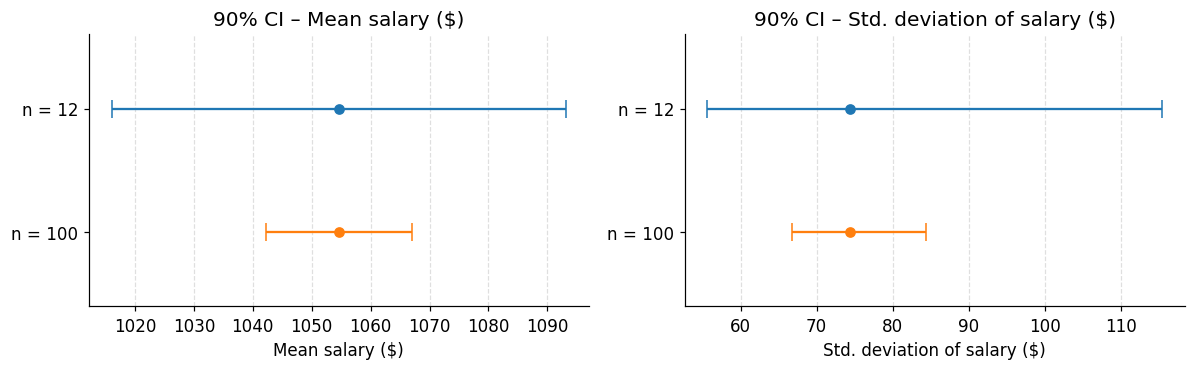

In [7]:
# Visual comparison of the intervals
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, small, big, point) in zip(axes, [("Mean salary ($)", ci_mean_small, ci_mean_big, x_bar),
                                                 ("Std. deviation of salary ($)", ci_std_small, ci_std_big, s)]):
    ax.errorbar(point, 1, xerr=[[point - small[0]], [small[1] - point]], fmt="o", capsize=6, label="n = 12")
    ax.errorbar(point, 0, xerr=[[point - big[0]], [big[1] - point]], fmt="o", capsize=6, label="n = 100")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["n = 100", "n = 12"]); ax.set_ylim(-0.6, 1.6)
    ax.set_title(f"90% CI – {name}"); ax.set_xlabel(name); ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

**Comment on the results.** The point estimates are the same in both cases (same mean and standard deviation), but the intervals for the n = 100 sample are much narrower. The width of the CI for the mean decreases roughly with $1/\sqrt{n}$ (the standard error shrinks and the t critical value gets closer to the normal one), and the CI for the standard deviation also becomes tighter and more symmetric around $s$ because the chi-square distribution becomes closer to a normal one as the degrees of freedom grow. With only 12 observations the estimate of the variability is very uncertain (the interval for $\sigma$ is wide), so the impression of a "great deal of variability" in the small sample cannot be judged reliably; the larger sample gives a much more precise estimate of both the average salary and its variability.

## Exercise 2 – NHANES (2015–2016): height and body weight
We use the **NHANES 2015–2016** dataset, produced by the National Center for Health Statistics (USA) as part of the National Health and Nutrition Examination Survey (https://wwwn.cdc.gov/nchs/nhanes/). The description of the variables is available at https://wwwn.cdc.gov/nchs/nhanes/search/default.aspx.\n\nVariables: `BMXHT` (height, cm), `BMXWT` (weight, kg), `RIAGENDR` (gender: 1 = male, 2 = female).

### 2a) Load the dataset and keep only gender, height and body weight\nNHANES data are published as separate SAS transport files (`.XPT`), one for each survey component, all sharing the participant identifier `SEQN`:\n- **DEMO_I** (Demographics) contains `RIAGENDR`;\n- **BMX_I** (Body Measures) contains `BMXHT` and `BMXWT`.\n\nThe cell below downloads both files directly from the CDC website and merges them on `SEQN`. If the download is blocked, it asks you to upload the two files manually.

In [10]:
import io
import requests

BASE_URL = "https://wwwn.cdc.gov/Nchs/Nhanes/2015-2016/"

def read_xpt(source):
    # Read a SAS transport (.XPT) file from a URL or from a local path
    if str(source).startswith("http"):
        resp = requests.get(source, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        resp.raise_for_status()
        return pd.read_sas(io.BytesIO(resp.content), format="xport")
    return pd.read_sas(source, format="xport")

try:
    demo = read_xpt(BASE_URL + "DEMO_I.XPT")    # Demographics: SEQN, RIAGENDR, ...
    bmx = read_xpt(BASE_URL + "BMX_I.XPT")      # Body Measures: SEQN, BMXHT, BMXWT, ...
except Exception as err:
    # Fallback: upload DEMO_I.XPT and BMX_I.XPT downloaded manually from the CDC website
    print("Automatic download failed:", err)
    from google.colab import files
    uploaded = files.upload()
    demo_file = next(f for f in uploaded if "demo" in f.lower())
    bmx_file = next(f for f in uploaded if "bmx" in f.lower())
    demo, bmx = read_xpt(demo_file), read_xpt(bmx_file)

print("Demographics file:", demo.shape, "| Body measures file:", bmx.shape)

# Merge the two components on the participant identifier SEQN (keeps participants present in both files)
raw = demo[["SEQN", "RIAGENDR"]].merge(bmx[["SEQN", "BMXHT", "BMXWT"]], on="SEQN", how="inner")
print("Merged dataset:", raw.shape)

Automatic download failed: Header record is not an XPORT file.


Saving DEMO_I.xpt to DEMO_I.xpt
Saving BMX_I.xpt to BMX_I.xpt
Demographics file: (9971, 47) | Body measures file: (9544, 26)
Merged dataset: (9544, 4)


In [12]:
import os

# Google Drive mount is unnecessary since we already uploaded the files locally.
# Let's double check that the required files exist in the current directory:
demo_exists = os.path.exists('DEMO_I.xpt')
bmx_exists = os.path.exists('BMX_I.xpt')

print(f"DEMO_I.xpt available: {demo_exists}")
print(f"BMX_I.xpt available: {bmx_exists}")
if demo_exists and bmx_exists:
    print("Ready to proceed! You can run the rest of the cells safely.")

DEMO_I.xpt available: True
BMX_I.xpt available: True
Ready to proceed! You can run the rest of the cells safely.


In [13]:
# Keep only gender, height and body weight
data = raw[["RIAGENDR", "BMXHT", "BMXWT"]].copy()
print("New shape:", data.shape)

# Check for missing entries (NaN)
print("\nMissing values per column:")
print(data.isna().sum())

# Remove rows with missing values
data = data.dropna().reset_index(drop=True)
print("\nShape after removing NaN:", data.shape)

# Gender is stored as a float in the XPT file -> convert to integer code and add readable labels
data["RIAGENDR"] = data["RIAGENDR"].astype(int)
data["Gender"] = data["RIAGENDR"].map({1: "Male", 2: "Female"})
print("\nParticipants per gender:")
print(data["Gender"].value_counts())
data.head()

New shape: (9544, 3)

Missing values per column:
RIAGENDR      0
BMXHT       775
BMXWT        99
dtype: int64

Shape after removing NaN: (8756, 3)

Participants per gender:
Gender
Female    4470
Male      4286
Name: count, dtype: int64


,RIAGENDR,BMXHT,BMXWT,Gender
0,1,184.5,94.8,Male
1,1,171.4,90.4,Male
2,1,170.1,83.4,Male
3,2,160.9,109.8,Female
4,2,164.9,55.2,Female


### 2b) 95% and 99% confidence intervals for the mean (by gender and overall)
The population variance is unknown, so the t-based interval is used with the critical values from Tabelul B. The groups have many observations (df > 100), so the last row ($\infty$) applies: **1.960** for 95% (column 0.975) and **2.576** for 99% (column 0.995), i.e. the standard normal quantiles.

In [14]:
def ci_mean(values, conf):
    """t-based confidence interval for the mean. Returns (mean, lower, upper)."""
    values = np.asarray(values, dtype=float)
    m = values.mean()
    se = stats.sem(values)                                   # s / sqrt(n)
    t_crit, _ = t_table(len(values) - 1, conf)               # critical value read from Tabelul B
    return m, m - t_crit * se, m + t_crit * se

variables = {"BMXHT": "Height (cm)", "BMXWT": "Weight (kg)"}
groups = {"Male": data[data["Gender"] == "Male"],
          "Female": data[data["Gender"] == "Female"],
          "All": data}

rows = []
for conf in (0.95, 0.99):
    for var, label in variables.items():
        for g_name, g_df in groups.items():
            m, lo, hi = ci_mean(g_df[var], conf)
            rows.append({"Confidence": f"{conf:.0%}", "Variable": label, "Group": g_name,
                         "n": len(g_df), "Mean": m, "Lower": lo, "Upper": hi, "Width": hi - lo})

ci_table = pd.DataFrame(rows)
ci_table.round(3)

,Confidence,Variable,Group,n,Mean,Lower,Upper,Width
0,95%,Height (cm),Male,4286,159.660,158.909,160.412,1.503
1,95%,Height (cm),Female,4470,150.680,150.099,151.261,1.162
2,95%,Height (cm),All,8756,155.076,154.594,155.558,0.963
3,95%,Weight (kg),Male,4286,69.706,68.762,70.650,1.887
4,95%,Weight (kg),Female,4470,63.626,62.809,64.443,1.634
5,95%,Weight (kg),All,8756,66.602,65.976,67.227,1.251
6,99%,Height (cm),Male,4286,159.660,158.673,160.648,1.975
7,99%,Height (cm),Female,4470,150.680,149.917,151.444,1.527
8,99%,Height (cm),All,8756,155.076,154.443,155.709,1.266
9,99%,Weight (kg),Male,4286,69.706,68.466,70.946,2.480


In [15]:
# Compare the width of the 95% and 99% intervals
pivot = ci_table.pivot_table(index=["Variable", "Group"], columns="Confidence", values="Width")
pivot["Ratio 99%/95%"] = pivot["99%"] / pivot["95%"]
pivot.round(3)

Confidence            95%    99%  Ratio 99%/95%
Variable    Group                              
Height (cm) All     0.963  1.266          1.314
            Female  1.162  1.527          1.314
            Male    1.503  1.975          1.314
Weight (kg) All     1.251  1.644          1.314
            Female  1.634  2.148          1.314
            Male    1.887  2.480          1.314

**Observations (2b).**
- The 99% intervals are wider than the 95% ones for every group and variable (about 1.31 times wider, the ratio of the critical values 2.576 / 1.960): a higher confidence level requires a wider interval.
- Intervals for the whole sample are narrower than those for each gender because the sample size is larger (smaller standard error).
- The intervals for men and women do not overlap for either variable (men are on average taller and heavier), so the gender difference is clearly visible. The overall interval lies between the two group intervals.
- Because the samples are large, all intervals are very narrow.

### 2c) 20 random samples of size 100
The whole cleaned dataset is treated as the population. Its means (computed in 2b for the full dataset and for each gender) are the *true* values.

In [16]:
rng = np.random.default_rng(42)     # fixed seed for reproducible results
n_samples, sample_size, conf = 20, 100, 0.95

# True population means (the whole dataset is the population)
true_means = {(var, g): g_df[var].mean() for var in variables for g, g_df in groups.items()}

records = []
for i in range(1, n_samples + 1):
    # Simple random sample without replacement of 100 rows from the population
    idx = rng.choice(len(data), size=sample_size, replace=False)
    sample = data.iloc[idx]
    sample_groups = {"Male": sample[sample["Gender"] == "Male"],
                     "Female": sample[sample["Gender"] == "Female"],
                     "All": sample}
    for var in variables:
        for g_name, g_df in sample_groups.items():
            m, lo, hi = ci_mean(g_df[var], conf)
            records.append({"Sample": i, "Variable": var, "Group": g_name, "n": len(g_df),
                            "Mean": m, "Lower": lo, "Upper": hi,
                            "Covers true mean": lo <= true_means[(var, g_name)] <= hi})

samples_ci = pd.DataFrame(records)
samples_ci.head(9).round(3)

,Sample,Variable,Group,n,Mean,Lower,Upper,Covers true mean
0,1,BMXHT,Male,47,162.962,155.782,170.141,True
1,1,BMXHT,Female,53,149.347,143.604,155.090,True
2,1,BMXHT,All,100,155.746,151.080,160.412,True
3,1,BMXWT,Male,47,71.660,62.833,80.487,True
4,1,BMXWT,Female,53,59.900,52.257,67.543,True
5,1,BMXWT,All,100,65.427,59.611,71.243,True
6,2,BMXHT,Male,39,151.095,141.128,161.062,True
7,2,BMXHT,Female,61,152.416,147.637,157.196,True
8,2,BMXHT,All,100,151.901,147.141,156.661,True


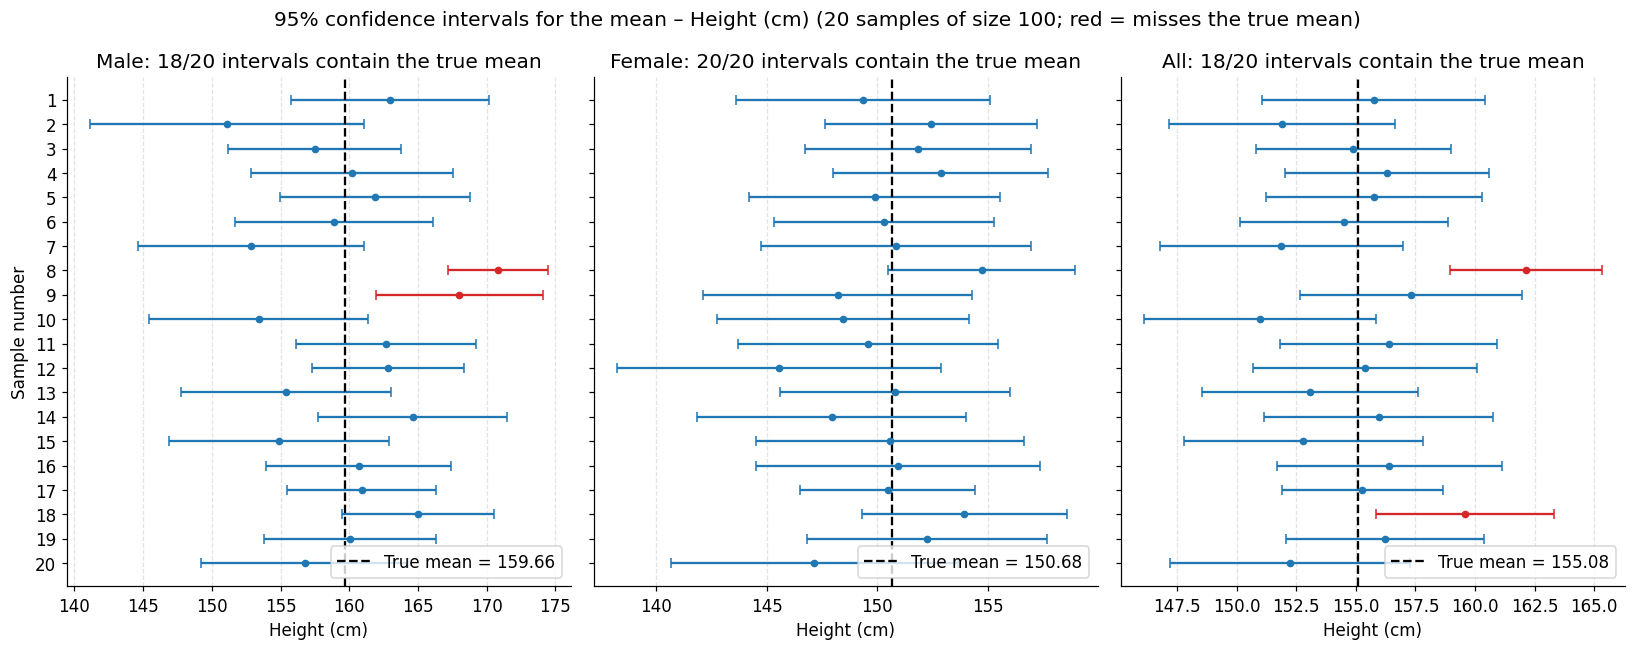

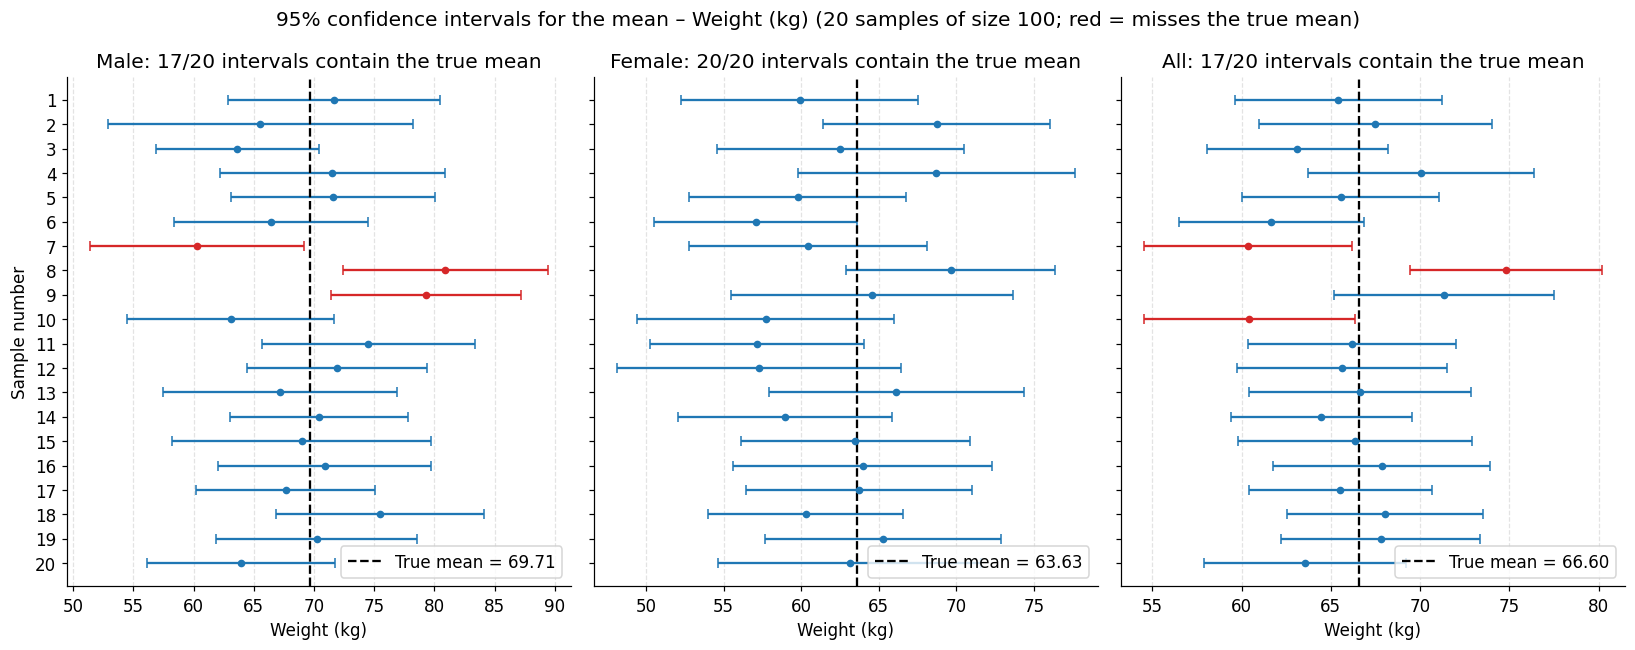

In [17]:
# Plot the 20 confidence intervals for each variable and group, with the true mean highlighted
colors = {True: "tab:blue", False: "tab:red"}   # red = interval that misses the true mean

for var, label in variables.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
    for ax, g_name in zip(axes, ["Male", "Female", "All"]):
        sub = samples_ci[(samples_ci["Variable"] == var) & (samples_ci["Group"] == g_name)]
        for _, r in sub.iterrows():
            ax.errorbar(r["Mean"], r["Sample"], xerr=[[r["Mean"] - r["Lower"]], [r["Upper"] - r["Mean"]]],
                        fmt="o", color=colors[bool(r["Covers true mean"])], capsize=3, markersize=4)
        ax.axvline(true_means[(var, g_name)], color="black", linestyle="--", linewidth=1.5,
                   label=f"True mean = {true_means[(var, g_name)]:.2f}")
        covered = int(sub["Covers true mean"].sum())
        ax.set_title(f"{g_name}: {covered}/{n_samples} intervals contain the true mean")
        ax.set_xlabel(label)
        ax.legend(loc="lower right")
        ax.grid(axis="x", linestyle="--", alpha=0.35)
    axes[0].set_ylabel("Sample number")
    axes[0].set_yticks(range(1, n_samples + 1))
    axes[0].invert_yaxis()
    plt.suptitle(f"95% confidence intervals for the mean – {label} (20 samples of size 100; red = misses the true mean)")
    plt.tight_layout()
    plt.show()

In [18]:
# Coverage summary: proportion of intervals that contain the true mean
coverage = samples_ci.groupby(["Variable", "Group"])["Covers true mean"].agg(["sum", "mean"])
coverage.columns = ["Intervals covering the true mean (of 20)", "Coverage rate"]
coverage

Intervals covering the true mean (of 20)  Coverage rate
Variable Group                                                          
BMXHT    All                                           18           0.90
         Female                                        20           1.00
         Male                                          18           0.90
BMXWT    All                                           17           0.85
         Female                                        20           1.00
         Male                                          17           0.85

**Comments (2c).**
- For each sample the critical value comes from Tabelul B: df = 99 → row 100 (1.984) for the whole sample and, for each gender subsample of about 50 observations, the nearest row (e.g. df = 49 → row 50 → 2.009).
- Each of the 20 intervals is centred on a different sample mean, so the intervals move around the true mean (dashed line) from sample to sample: this is sampling variability.
- A 95% confidence level means that, in the long run, about 95% of the intervals contain the true mean, so about 1 interval out of 20 is expected to miss it (red). The coverage table shows how many actually do; a result of 18–20 out of 20 is in line with theory, and small deviations are due to the small number of repetitions (only 20).
- The intervals for the gender groups are wider than those for the entire sample, because each gender subsample has only about 50 observations.
- Intervals computed on samples of size 100 are much wider than those computed from the entire dataset in 2b, which shows how the sample size controls precision.
- Changing the seed in `np.random.default_rng(42)` gives different samples and possibly different numbers of intervals missing the true mean.